# Financial Inclusion in Africa

**Team:** Andi, Muhammet  
**Ziel:** Vorhersagen, ob eine Person ein Bankkonto hat (`bank_account`: Yes / No).  
**Daten:** Zindi, Umfragen aus Kenia, Ruanda, Tansania und Uganda (2016–2018).

## Milestone 0: Daten laden

In [6]:
import pandas as pd  # Werkzeugkasten pandas holen, Spitzname pd  # Kap. 15

In [7]:
df_train = pd.read_csv("data/Train.csv")  # CSV-Datei einlesen und in df_train speichern  # Kap. 15
df_train.shape  # Anzahl Zeilen und Spalten anzeigen  # Kap. 15

(23524, 13)

**Ergebnis Milestone 0:**
- Trainingsdaten: 23.524 Zeilen (Personen), 13 Spalten.
- Testdaten: 10.086 Zeilen, 12 Spalten. Es fehlt nur `bank_account`, das sagen wir später vorher.
- Fast alle Spalten sind Text (Kategorien), nur `year`, `household_size` und `age_of_respondent` sind Zahlen.

## Milestone 1: EDA (erkundende Datenanalyse)

In [8]:
df_train.head()  # die ersten 5 Zeilen der Tabelle anzeigen  # Kap. 15

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


**Erste Zeilen:** Jede Zeile ist eine befragte Person, jede Spalte eine Information über sie (Land, Jahr, Wohnort, Handy, Alter, Bildung, Arbeit usw.).
Die Spalte `bank_account` ist unser **Ziel (target)**: Yes = hat ein Konto, No = hat kein Konto.

In [9]:
df_train.info()  # Überblick: Spaltennamen, Datentypen, Anzahl gefüllter Werte  # Kap. 15

<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(3), str(10)
memory usage: 2.3 MB


**Datentypen:** 10 der 13 Spalten sind Text (Kategorien), nur `year`, `household_size` und `age_of_respondent` sind Zahlen.
Für die Modelle müssen wir die Text-Spalten später in Zahlen umwandeln (Encoding).
`uniqueid` ist nur eine Personen-Nummer und hilft bei der Vorhersage nicht.

In [10]:
df_test = pd.read_csv("data/Test.csv")  # Testdaten einlesen und in df_test speichern  # Kap. 15
df_test.shape  # Anzahl Zeilen und Spalten anzeigen  # Kap. 15

(10086, 12)

In [11]:
df_train["bank_account"].value_counts()  # zählen, wie oft Yes und No vorkommt  # Kap. 15

bank_account
No     20212
Yes     3312
Name: count, dtype: int64

In [12]:
df_train["bank_account"].value_counts(normalize=True)  # dasselbe als Anteil (0 bis 1)  # Kap. 15

bank_account
No     0.859208
Yes    0.140792
Name: proportion, dtype: float64

**Zielvariable:** 20.212 Personen (85,9 %) haben **kein** Bankkonto, nur 3.312 (14,1 %) haben eins.
Die Daten sind also **unausgewogen (imbalanced)**.
Ein Modell, das immer „No“ sagt, wäre schon zu 85,9 % richtig. Unser Modell muss besser sein.

In [13]:
df_train.isna().sum()  # pro Spalte zählen, wie viele Werte fehlen  # Kap. 17

country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0
dtype: int64

**Fehlende Werte:** In keiner Spalte fehlt ein Wert. Wir müssen nichts auffüllen oder löschen.

In [14]:
df_train.duplicated().sum()  # zählen, wie viele Zeilen doppelt vorkommen  # neu

np.int64(0)

In [15]:
import matplotlib.pyplot as plt  # Werkzeugkasten für Diagramme holen  # Kap. 20

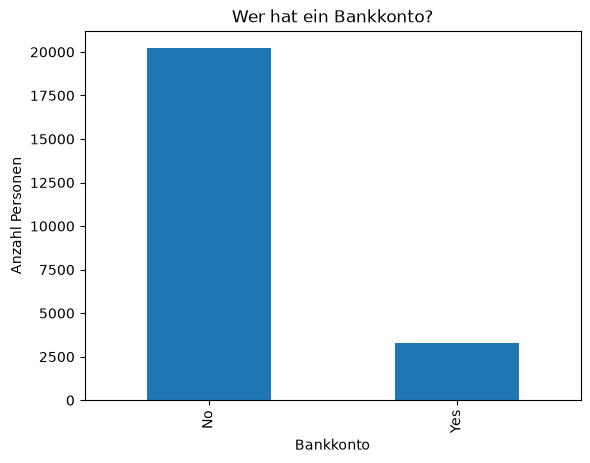

In [16]:
df_train["bank_account"].value_counts().plot(kind="bar")  # Balkendiagramm Yes/No  # Kap. 20
plt.title("Wer hat ein Bankkonto?")  # Überschrift  # Kap. 20
plt.xlabel("Bankkonto")  # Beschriftung unten  # Kap. 20
plt.ylabel("Anzahl Personen")  # Beschriftung links  # Kap. 20
plt.show()  # Diagramm anzeigen  # Kap. 20

In [17]:
pd.crosstab(df_train["country"], df_train["bank_account"], normalize="index")  # Anteil Yes/No pro Land  # Kap. 17

bank_account,No,Yes
country,,
Kenya,0.749341,0.250659
Rwanda,0.885175,0.114825
Tanzania,0.908308,0.091692
Uganda,0.913851,0.086149
